# 06 — A time-varying world risk price: USD and EUR

Audit the global conditioning variables first, then replace the constant world risk price with a linear
function of lagged information. Keep the same five-series equity/FX system, FX VAR(6), and scalar /
diagonal covariance specifications from notebook 05. Local and currency prices are **re-estimated
jointly but remain constant through time**.

Run `05_currency_risk.ipynb`, then **Run All** here in the existing Miniconda **base** kernel.
The same frozen 321-month working sample is used by default; no data are downloaded or revised.
The final table compares constant versus time-varying world prices within each investor perspective.

In [1]:
# Adjustable settings. Never fetch data or change the frozen snapshot in this notebook.
SNAPSHOT = "data/fixed_2026-11-13/from_2000-01"
ANALYSIS_START = None
ANALYSIS_END = None
FX_VAR_LAGS = 6  # Must match the notebook 05 benchmark.
WORLD_INSTRUMENTS = ["short_rate_change_lag1_pp", "term_spread_change_lag1_pp", "credit_spread_lag1_pp"]
SE_STEP_TOL = 0.01  # Withhold uncertainty if risk-price SEs move by more than 1% at half Hessian step.
COVARIANCE_MODELS = ["scalar", "diagonal"]
START_DYNAMICS = [(0.05, 0.90), (0.10, 0.75)]  # alpha, beta
MAX_ITER = 1600
TEST_LAGS = 12
REUSE_FITS = True  # False forces re-estimation; model code and settings enter the cache key.
MODEL_VERSION = "time_varying_world_v1"

from pathlib import Path
from io import BytesIO
import hashlib
import importlib.metadata
import json
import os
import platform
import sys

ROOT = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import softmax
from scipy.stats import norm, chi2
from packaging.version import Version
sm_version = importlib.metadata.version("statsmodels")
if Version(sm_version) < Version("0.15.0"):
    raise RuntimeError("Run %pip install --upgrade statsmodels==0.15.0, then Restart Kernel and Run All.")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__ != sm_version:
    raise RuntimeError("statsmodels was updated. Restart Kernel and Run All to discard old imports.")
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
import warnings
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.sm_exceptions import InterpolationWarning
from IPython.display import display, Markdown

versions = {p: importlib.metadata.version(p) for p in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib"]}
print("Python:", sys.executable)
print("Packages:", versions)
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 40)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18})
source = ROOT / SNAPSHOT
manifest = json.loads((source / "manifest.json").read_text())
raw = (source / "dataset.csv").read_bytes()
if not manifest.get("sealed") or hashlib.sha256(raw).hexdigest() != manifest["exports"]["dataset.csv"]:
    raise ValueError("The frozen dataset is not sealed or its checksum differs.")
data = pd.read_csv(BytesIO(raw), index_col=0, float_precision="round_trip")
data.index = pd.PeriodIndex(data.index, freq="M", name="month")
if not data.index.equals(pd.period_range(data.index[0], data.index[-1], freq="M")):
    raise ValueError("Missing or duplicate months.")
data = data.loc[ANALYSIS_START:ANALYSIS_END].copy()
if len(data) < max(120, 5 * TEST_LAGS) or not 2 <= TEST_LAGS <= 24:
    raise ValueError("Use at least 120 months and TEST_LAGS from 2 to 24 for this initial fit.")

if not isinstance(FX_VAR_LAGS, int) or not 0 <= FX_VAR_LAGS <= 12:
    raise ValueError("FX_VAR_LAGS must be an integer from 0 to 12.")
if not COVARIANCE_MODELS or len(set(COVARIANCE_MODELS)) != len(COVARIANCE_MODELS) or any(
        c not in ["scalar", "diagonal"] for c in COVARIANCE_MODELS):
    raise ValueError("Choose scalar, diagonal, or both covariance models without duplicates.")
if any(a <= 0 or b <= 0 or a+b >= 1 for a,b in START_DYNAMICS):
    raise ValueError("Starting alpha/beta must be positive and sum to less than one.")
# Estimate scalar first if both are requested, to initialise the nested diagonal model.
COVARIANCE_MODELS = [c for c in ["scalar", "diagonal"] if c in COVARIANCE_MODELS]
ASSETS = ["World", "US", "Hungary", "HUF FX", "Other FX"]
FX_NAMES = {"USD": ["HUF", "EUR"], "EUR": ["HUF", "USD"]}
fx_raw = (source / "raw" / "ecb_fx.csv").read_bytes()
fx_source_sha256 = hashlib.sha256(fx_raw).hexdigest()
if fx_source_sha256 != manifest["sources"]["ecb_fx.csv"]["sha256"]:
    raise ValueError("Frozen ECB source checksum differs.")
ecb = pd.read_csv(BytesIO(fx_raw), usecols=["TIME_PERIOD", "CURRENCY", "OBS_VALUE"], float_precision="round_trip")
ecb["TIME_PERIOD"] = pd.to_datetime(ecb["TIME_PERIOD"])
ecb["OBS_VALUE"] = pd.to_numeric(ecb["OBS_VALUE"], errors="raise")
ecb = ecb.pivot(index="TIME_PERIOD", columns="CURRENCY", values="OBS_VALUE").sort_index()
ecb = ecb.groupby(ecb.index.to_period("M")).last()
fx_usd = pd.DataFrame({"HUF": -np.log(ecb["HUF"] / ecb["USD"]).diff(),
                       "EUR": np.log(ecb["USD"]).diff()}) * 100
fx_eur = pd.DataFrame({"HUF": fx_usd["HUF"] - fx_usd["EUR"], "USD": -fx_usd["EUR"]})
np.testing.assert_allclose(fx_usd.loc[data.index].to_numpy(),
                          data[["fx_huf_usd", "fx_eur_usd"]].to_numpy()*100, atol=1e-11, rtol=0)
np.testing.assert_allclose(fx_eur.loc[data.index, "HUF"], data["fx_huf_eur"]*100, atol=1e-11, rtol=0)
samples, designs, scales_by_currency = {}, {}, {}
for currency, fx in [("USD", fx_usd), ("EUR", fx_eur)]:
    equities = data[[f"rx_{a}_{currency.lower()}" for a in ["world", "us", "hu"]]].to_numpy()*100
    y = np.c_[equities, fx.loc[data.index].to_numpy()]
    scales = y.std(axis=0, ddof=1)
    lagged = [(fx/scales[3:]).shift(lag).loc[data.index].to_numpy() for lag in range(1, FX_VAR_LAGS+1)]
    x = np.c_[np.ones(len(data)), np.concatenate(lagged, axis=1)] if lagged else np.ones((len(data),1))
    if not np.isfinite(y).all() or not np.isfinite(x).all() or not (scales>0).all():
        raise ValueError("Missing FX history or non-finite data. Reduce FX_VAR_LAGS or move ANALYSIS_START later.")
    if np.linalg.matrix_rank(x) != x.shape[1]:
        raise ValueError("FX mean design is rank deficient.")
    samples[currency], designs[currency], scales_by_currency[currency] = y, x, scales
# Check the observed USD-to-EUR transformation, including the two different cash proxies.
transform = np.eye(5)
transform[:3,4], transform[3,4], transform[4,4] = -1., -1., -1.
converted = samples["USD"] @ transform.T
converted[:,:3] += ((data["rf_usd"]-data["rf_eur_proxy"])*100).to_numpy()[:,None]
np.testing.assert_allclose(converted, samples["EUR"], atol=1e-10, rtol=0)

BASELINE = ROOT / "output" / "05_currency_risk" / source.parent.name / f"{data.index[0]}_{data.index[-1]}" / f"var{FX_VAR_LAGS}"
CANDIDATES = ["short_rate_change_lag1_pp", "term_spread_change_lag1_pp", "credit_spread_lag1_pp"]
if not WORLD_INSTRUMENTS or len(set(WORLD_INSTRUMENTS)) != len(WORLD_INSTRUMENTS) or any(
        c not in CANDIDATES for c in WORLD_INSTRUMENTS):
    raise ValueError("Choose a nonempty, unique subset of the three audited global instruments.")
instrument_id=hashlib.sha256(json.dumps(WORLD_INSTRUMENTS).encode()).hexdigest()[:8]
OUT = ROOT / "output" / "06_time_varying_world" / source.parent.name / f"{data.index[0]}_{data.index[-1]}" / f"var{FX_VAR_LAGS}_z{instrument_id}"
OUT.mkdir(parents=True,exist_ok=True)
display(pd.DataFrame({"first":[str(data.index[0])],"last":[str(data.index[-1])],"months":[len(data)],
                      "series":[5],"global_predictors":[len(WORLD_INSTRUMENTS)],"FX_VAR_lags":[FX_VAR_LAGS]}))

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8'}


,first,last,months,series,global_predictors,FX_VAR_lags
0,2000-01,2026-09,321,5,3,6


## 1. Audit the instruments before estimating prices

“Instruments” means lagged conditioning information, as in the paper. Use the **same global design**
for USD and EUR. The three candidates were specified before inspecting pricing results:

| Variable already in the frozen panel | Definition at return month $t$ |
|---|---|
| `short_rate_change_lag1_pp` | $TB3MS_{t-1}-TB3MS_{t-2}$ |
| `term_spread_change_lag1_pp` | $(GS10-TB3MS)_{t-1}-(GS10-TB3MS)_{t-2}$ |
| `credit_spread_lag1_pp` | $(BAA-AAA)_{t-1}$ |

Rebuild these from the sealed raw FRED file, including pre-2000 observations, and match all working
months. **Do not lag them again.** No dividend-yield predictor is included, as previously agreed.
The Treasury-bill change substitutes for the paper's Eurodollar-rate change; the credit spread stays
in levels. Inflation gaps and the Hungary regime indicator are reserved for later local/FX-price work.

Audit missingness, persistence, ADF (unit-root null), KPSS (level-stationarity null), extreme values,
correlation, rank, VIF and conditioning. These are specification screens, not a p-value selection rule.
Retain the three planned variables when the accounting/rank checks pass; flag persistence and crisis
observations rather than winsorising or choosing predictors for significant pricing results.

The snapshot uses downloaded historical vintages, not release-date vintages. Monthly lags express our
information-timing approximation; this notebook is an in-sample conditional-pricing study.

,used,mean_pp,sd_pp,AR1,ADF_p,ADF_lags,KPSS_p_report,VIF,max_abs_z,extreme_month,max_lag_error
instrument,,,,,,,,,,,
short_rate_change_lag1_pp,True,-0.00421,0.18770,0.54897,0.00000,2,>=0.10,1.38055,6.53054,2020-04,0.0
term_spread_change_lag1_pp,True,-0.00000,0.23599,0.30734,0.00000,2,>=0.10,1.35911,4.15265,2022-08,0.0
credit_spread_lag1_pp,True,0.99056,0.39931,0.95803,0.00048,5,>=0.10,1.02105,5.98390,2009-01,0.0


,short_rate_change_lag1_pp,term_spread_change_lag1_pp,credit_spread_lag1_pp
short_rate_change_lag1_pp,1.0000,-0.5103,-0.1246
term_spread_change_lag1_pp,-0.5103,1.0000,0.0023
credit_spread_lag1_pp,-0.1246,0.0023,1.0000


Selected design: rank 4/4, condition number 1.792.
Retain the planned set. The credit spread is persistent; keep crisis extremes visible and revisit them in robustness work.


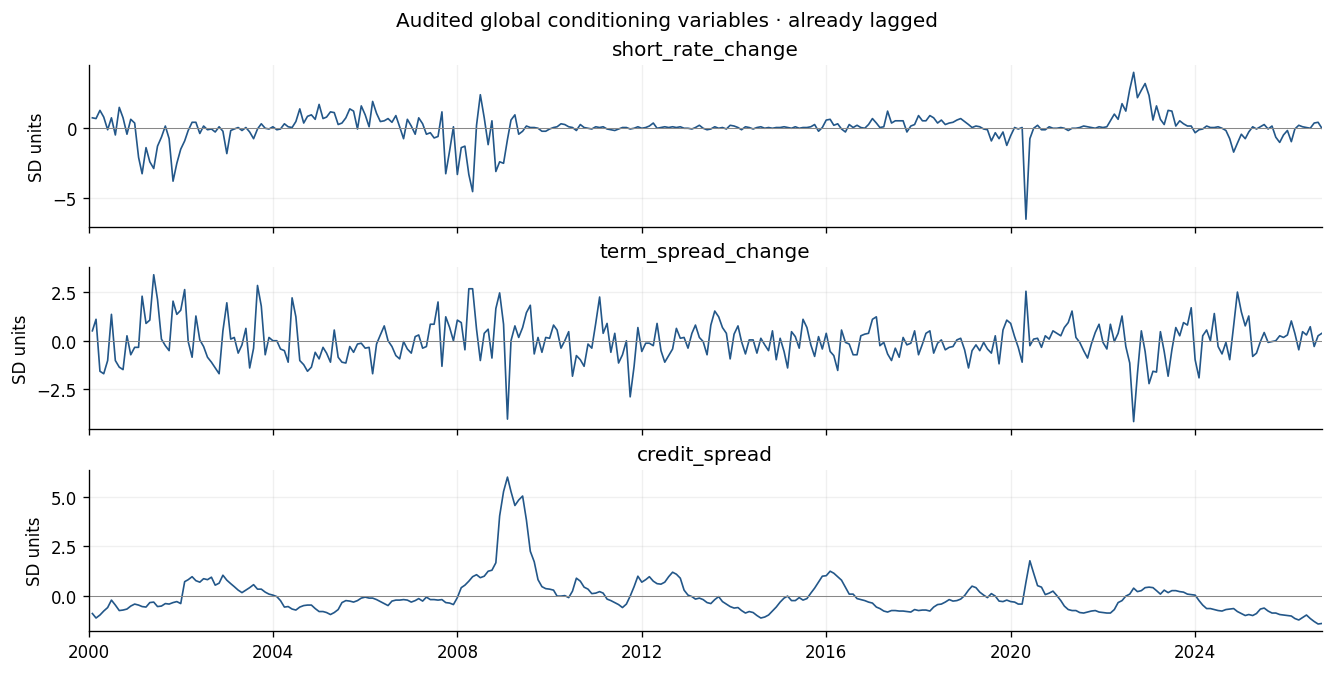

In [2]:
fred_raw=(source/"raw"/"fred.csv").read_bytes()
fred_sha256=hashlib.sha256(fred_raw).hexdigest()
if fred_sha256 != manifest["sources"]["fred.csv"]["sha256"]: raise ValueError("Frozen FRED checksum differs.")
fred=pd.read_csv(BytesIO(fred_raw),index_col=0,float_precision="round_trip")
fred.index=pd.PeriodIndex(fred.index,freq="M")
if not fred.index.is_unique: raise ValueError("Duplicate FRED months.")
fred=fred.reindex(pd.period_range(fred.index.min(),fred.index.max(),freq="M"))
rebuilt=pd.DataFrame({CANDIDATES[0]:fred["TB3MS"].diff().shift(1),
                     CANDIDATES[1]:(fred["GS10"]-fred["TB3MS"]).diff().shift(1),
                     CANDIDATES[2]:(fred["BAA"]-fred["AAA"]).shift(1)}).loc[data.index]
instruments=data[CANDIDATES].copy()
np.testing.assert_allclose(rebuilt.to_numpy(),instruments.to_numpy(),atol=1e-12,rtol=0)
if not np.isfinite(instruments.to_numpy()).all(): raise ValueError("Missing conditioning values.")
centres,spreads=instruments.mean(),instruments.std(ddof=1)
if not spreads.gt(0).all(): raise ValueError("Constant conditioning variable.")
standardised=(instruments-centres)/spreads
full_design=np.c_[np.ones(len(data)),standardised.to_numpy()]
audit_rows=[]
for j,name in enumerate(CANDIDATES):
    values=instruments[name].to_numpy()
    adf=adfuller(values,maxlag=12,regression="c",autolag="AIC",result_object=False)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always",InterpolationWarning)
        kp=kpss(values,regression="c",nlags="auto",result_object=False)
    bound=(">=" if kp[1]>=.10 else "<=") if any(issubclass(w.category,InterpolationWarning) for w in caught) else ""
    audit_rows.append({"instrument":name,"used":name in WORLD_INSTRUMENTS,"mean_pp":centres[name],
        "sd_pp":spreads[name],"AR1":instruments[name].autocorr(),"ADF_p":adf[1],"ADF_lags":adf[2],
        "KPSS_p_report":f"{bound}{kp[1]:.2f}","VIF":variance_inflation_factor(full_design,j+1),
        "max_abs_z":standardised[name].abs().max(),"extreme_month":str(standardised[name].abs().idxmax()),
        "max_lag_error":np.max(np.abs(rebuilt[name]-instruments[name]))})
audit=pd.DataFrame(audit_rows).set_index("instrument")
Z=np.c_[np.ones(len(data)),standardised[WORLD_INSTRUMENTS].to_numpy()]
if np.linalg.matrix_rank(Z)!=Z.shape[1]: raise ValueError("World-price design is rank deficient.")
transform_table=pd.DataFrame({"mean_pp":centres,"sd_pp":spreads,"used":instruments.columns.isin(WORLD_INSTRUMENTS)})
conditioning=pd.DataFrame(Z,index=data.index,columns=["constant"]+WORLD_INSTRUMENTS)
display(audit.round(5))
display(instruments.corr().round(4))
print(f"Selected design: rank {np.linalg.matrix_rank(Z)}/{Z.shape[1]}, condition number {np.linalg.cond(Z):.3f}.")
print("Retain the planned set. The credit spread is persistent; keep crisis extremes visible and revisit them in robustness work.")
fig,axes=plt.subplots(3,1,figsize=(11,5.5),sharex=True,layout="constrained")
for ax,name in zip(axes,CANDIDATES):
    ax.plot(data.index.to_timestamp("M"),standardised[name],lw=1,color="#235789")
    ax.axhline(0,color="#888888",lw=.6)
    ax.set(ylabel="SD units",title=name.replace("_lag1_pp",""),xlim=(data.index[0].start_time,data.index[-1].end_time))
fig.suptitle("Audited global conditioning variables · already lagged")
plt.savefig(OUT/"01_conditioning_variables.png",dpi=160,bbox_inches="tight")
plt.show();plt.close()

## 2. Change only the world-price functional form

Use the linear formulation in [Antell and Vaihekoski, equation (15)](https://www.efmaefm.org/0EFMAMEETINGS/EFMA%20ANNUAL%20MEETINGS/2005-Milan/papers/14-antell_paper.pdf)
(equation numbers refer to the supplied April 2005 draft):

$$\boxed{\lambda_{W,t}=\kappa_0+\sum_{j=1}^{K}\kappa_j\widetilde Z_{j,t-1},\qquad
\widetilde Z_j=(Z_j-\bar Z_j)/s_j.}$$

The stored columns already have their lag. Demean/scale over the estimation sample for conditioning;
this is an equivalent parameterisation of the raw-variable linear model. $\kappa_0$ equals the sample
average fitted world price, and slopes measure the price change for a one-SD predictor increase.
This is not an out-of-sample forecasting exercise. The linear specification allows negative prices.

For each equity $i\in\{W,US,HU\}$, keep

$$\mu_{i,t}=\lambda_{W,t}H_{iW,t}+\lambda_H H_{iH,t}+\lambda_O H_{iO,t}
+\mathbf1_{i=US}\lambda_{US}H_{US,US,t}+\mathbf1_{i=HU}\lambda_{HU}H_{HU,HU,t}.$$

The two FX prices and two local prices are **constant coefficients, jointly re-estimated** in the new
model. The FX factors, separate VAR(6) mean equations and stationary BEKK covariance model remain
as in notebook 05. The scalar model is the primary benchmark; diagonal BEKK is a sensitivity check.

The `constant` restriction sets all $K$ world slopes to zero. With $K=3$, time variation adds only
three parameters: **48 → 51** under scalar covariance, **56 → 59** under diagonal covariance.

In [3]:
PRICE_SCALE = 0.01
N = 5
TRI = np.tril_indices(N)

def layout(x, z, varying, covariance_model):
    k = 5 + (z.shape[1]-1 if varying else 0)
    g = 2 * x.shape[1]
    dynamics = N * 2 if covariance_model == 'diagonal' else 2
    return k, g, dynamics

def unpack(theta, scales, x, z, varying, covariance_model):
    k, g, dynamics = layout(x, z, varying, covariance_model)
    q = len(theta)
    prices, dp = np.zeros(5), np.zeros((q, 5))
    prices[:] = PRICE_SCALE * theta[:5]
    dp[np.arange(5), np.arange(5)] = PRICE_SCALE
    gamma = theta[k:k+g].reshape(2, x.shape[1])
    C, dC = np.zeros((N, N)), np.zeros((q, N, N))
    for offset, (i, j) in enumerate(zip(*TRI)):
        index = k + g + offset
        value = np.exp(theta[index]) if i == j else theta[index]
        C[i, j] = scales[i] * value
        dC[index, i, j] = scales[i] * (value if i == j else 1.0)
    intercept = C @ C.T
    dintercept = dC @ C.T + C @ dC.transpose(0, 2, 1)
    weights = softmax(np.c_[np.zeros(dynamics // 2), theta[-dynamics:].reshape(-1, 2)], axis=1)
    alpha, beta = np.broadcast_to(weights[:, 1], N), np.broadcast_to(weights[:, 2], N)
    da, db = np.zeros((q, N)), np.zeros((q, N))
    for i in range(N):
        offset = i if covariance_model == 'diagonal' else 0
        u, v = q - dynamics + 2 * offset, q - dynamics + 2 * offset + 1
        da[u, i], da[v, i] = alpha[i] * (1-alpha[i]), -alpha[i]*beta[i]
        db[u, i], db[v, i] = -alpha[i]*beta[i], beta[i]*(1-beta[i])
    a, b = np.sqrt(alpha), np.sqrt(beta)
    da, db = da / (2*a), db / (2*b)
    aa, bb = np.outer(a, a), np.outer(b, b)
    daa = da[:, :, None]*a[None, None, :] + a[None, :, None]*da[:, None, :]
    dbb = db[:, :, None]*b[None, None, :] + b[None, :, None]*db[:, None, :]
    denominator = 1-aa-bb
    target = intercept / denominator
    dtarget = dintercept / denominator + intercept*(daa+dbb)/denominator**2
    return prices, dp, gamma, intercept, dintercept, aa, daa, bb, dbb, target, dtarget, alpha, beta

def world_indices(z, varying):
    return np.r_[0, np.arange(5, 5+z.shape[1]-1)] if varying else np.array([0])

## 3. Joint likelihood and optimisation

The Gaussian QML loss is unchanged. Forward analytic derivatives include the time-varying world
price, every nuisance parameter and the complete covariance recursion. Full BFGS followed by
bounded L-BFGS-B polishing uses several deterministic/nested starts. Inspect the starting-point
results; successful convergence does not establish a global optimum.

In [4]:
def filter_model(theta, y, x, z, scales, varying, covariance_model):
    prices, dp, gamma, intercept, dintercept, aa, daa, bb, dbb, target, dtarget, alpha, beta = unpack(theta, scales, x, z, varying, covariance_model)
    H, dH = target.copy(), dtarget.copy()
    n, q = len(y), len(theta)
    k, g, _ = layout(x, z, varying, covariance_model)
    losses, scores = np.empty(n), np.empty((n, q))
    covariances, means, residuals = np.empty((n, N, N)), np.empty_like(y), np.empty_like(y)
    indices = world_indices(z, varying)
    world_design = z if varying else np.ones((n, 1))
    world_prices = PRICE_SCALE * (world_design @ theta[indices])
    world_gradient = np.zeros((n, q))
    world_gradient[:, indices] = PRICE_SCALE * world_design
    for t in range(n):
        if not np.isfinite(H).all() or np.max(np.diag(H)) > 1e8:
            raise FloatingPointError('Unstable covariance recursion')
        chol, inverse = np.linalg.cholesky(H), np.linalg.inv(H)
        mu, dmu = np.zeros(N), np.zeros((q, N))
        for price, factor in [(0, 0), (3, 3), (4, 4)]:
            value = world_prices[t] if price == 0 else prices[price]
            derivative = world_gradient[t] if price == 0 else dp[:, price]
            mu[:3] += value * H[:3, factor]
            dmu[:, :3] += value * dH[:, :3, factor] + derivative[:, None] * H[None, :3, factor]
        for asset in (1, 2):
            mu[asset] += prices[asset] * H[asset, asset]
            dmu[:, asset] += prices[asset]*dH[:, asset, asset] + dp[:, asset]*H[asset, asset]
        mu[3:] = scales[3:] * (gamma @ x[t])
        for j in range(2):
            start = k + j*x.shape[1]
            dmu[start:start+x.shape[1], 3+j] = scales[3+j]*x[t]
        error, de = y[t]-mu, -dmu
        v = inverse @ error
        losses[t] = .5*(N*np.log(2*np.pi)+2*np.log(np.diag(chol)).sum()+error@v)
        scores[t] = .5*np.einsum('ij,kij->k', inverse-np.outer(v,v), dH) + de@v
        covariances[t], means[t], residuals[t] = H, mu, error
        shock = np.outer(error, error)
        dshock = de[:, :, None]*error[None, None, :] + error[None, :, None]*de[:, None, :]
        dH = dintercept + daa*shock + aa*dshock + dbb*H + bb*dH
        H = intercept + aa*shock + bb*H
    return {'losses':losses, 'scores':scores, 'H':covariances, 'mu':means, 'errors':residuals,
            'prices':prices, 'world_prices':world_prices, 'world_coefficients':PRICE_SCALE*theta[indices], 'gamma':gamma, 'intercept':intercept, 'target':target, 'alpha':alpha, 'beta':beta}

def objective(theta, y, x, z, scales, varying, covariance_model):
    try:
        with np.errstate(over='raise', invalid='raise', divide='raise'):
            f = filter_model(theta, y, x, z, scales, varying, covariance_model)
        if not np.isfinite(f['losses']).all() or not np.isfinite(f['scores']).all():
            raise FloatingPointError('Non-finite likelihood or gradient')
        return f['losses'].mean(), f['scores'].mean(axis=0)
    except (FloatingPointError, np.linalg.LinAlgError):
        return 1e8 + theta@theta, 2*theta

In [5]:
def initial_theta(y, x, z, scales, varying, covariance_model, alpha=.05, beta=.90):
    k, g, dynamics = layout(x, z, varying, covariance_model)
    gamma = np.linalg.lstsq(x, y[:, 3:]/scales[3:], rcond=None)[0].T
    centred = y.copy()
    centred[:, 3:] -= (x @ gamma.T)*scales[3:]
    covariance = np.cov(centred, rowvar=False)
    remaining = 1-alpha-beta
    C = np.linalg.cholesky(remaining*covariance/np.outer(scales,scales))
    chol = [np.log(C[i,j]) if i==j else C[i,j] for i,j in zip(*TRI)]
    world = y[:,0].mean()/covariance[0,0]
    prices = [world] + [(y[:,i].mean()-world*covariance[i,0])/covariance[i,i] for i in (1,2)]
    prices += [0.,0.]
    return np.r_[np.asarray(prices)/PRICE_SCALE, np.zeros(k-5), gamma.ravel(), chol,
                 np.tile([np.log(alpha/remaining),np.log(beta/remaining)], dynamics//2)]

def constant_to_varying(theta, n_slopes):
    return np.r_[theta[:5], np.zeros(n_slopes), theta[5:]]

def scalar_to_diagonal(theta):
    return np.r_[theta[:-2], np.tile(theta[-2:], N)]

def parameter_bounds(x, z, varying, covariance_model):
    k,g,dynamics = layout(x, z, varying, covariance_model)
    cov_bounds = [(-8.,3.) if i==j else (-4.,4.) for i,j in zip(*TRI)]
    return [(-100.,100.)]*k + [(-3.,3.)]*g + cov_bounds + [(-10.,10.)]*dynamics

def fit_starts(y, x, z, scales, varying, covariance_model, starts, maxiter=1600):
    bounds = np.asarray(parameter_bounds(x, z, varying, covariance_model))
    args = (y, x, z, scales, varying, covariance_model)
    runs, solutions = [], []
    for i, start in enumerate(starts, 1):
        # Full BFGS handles the weak price/covariance directions better than limited memory alone.
        coarse = minimize(objective, start, args=args, method='BFGS', jac=True,
                          options={'maxiter':maxiter, 'gtol':1e-6})
        # Restore numerical bounds after the exploratory BFGS step, then verify constrained convergence.
        projected = np.clip(coarse.x, bounds[:,0], bounds[:,1])
        result = minimize(objective, projected, args=args, method='L-BFGS-B', jac=True, bounds=bounds,
                          options={'maxiter':maxiter, 'ftol':1e-13, 'gtol':1e-7, 'maxls':50, 'maxcor':50})
        gradient = float(np.max(np.abs(result.jac)))
        print(f'  start {i}: success={result.success}, NLL={result.fun:.9f}, gradient={gradient:.2e}, '
              f'iterations={coarse.nit}+{result.nit}', flush=True)
        runs.append({'start':i, 'success':bool(result.success), 'mean_nll':float(result.fun),
                     'max_abs_gradient':gradient, 'iterations':int(coarse.nit+result.nit),
                     'BFGS_success':bool(coarse.success), 'polish_iterations':int(result.nit),
                     'message':str(result.message)})
        solutions.append(result)
    valid = [r for r in solutions if r.success and np.isfinite(r.fun) and r.fun<1e7
             and np.max(np.abs(r.jac))<1e-4]
    if not valid:
        raise RuntimeError('No converged fit with a small gradient; inspect starts and MAX_ITER.')
    best = min(valid, key=lambda r:r.fun)
    lower = [r for r in solutions if np.isfinite(r.fun) and r.fun<best.fun-1e-7]
    if lower:
        raise RuntimeError('A lower nonconverged candidate exists. Increase MAX_ITER before inference.')
    return best, runs

def numerical_gradient(function, theta, step=1e-5):
    result=np.empty_like(theta)
    for j in range(len(theta)):
        delta=step*(1+abs(theta[j])); plus=theta.copy();minus=theta.copy()
        plus[j]+=delta;minus[j]-=delta
        result[j]=(function(plus)-function(minus))/(2*delta)
    return result

def loss_hessian(theta, y, x, z, scales, varying, covariance_model, step=1e-4):
    result=np.empty((len(theta),len(theta)))
    for j in range(len(theta)):
        delta=step*(1+abs(theta[j]));plus=theta.copy();minus=theta.copy()
        plus[j]+=delta;minus[j]-=delta
        result[:,j]=(objective(plus,y,x,z,scales,varying,covariance_model)[1]-objective(minus,y,x,z,scales,varying,covariance_model)[1])/(2*delta)
    return (result+result.T)/2

def var_radius(gamma):
    lags=(gamma.shape[1]-1)//2
    if not lags: return 0.
    top=np.concatenate([gamma[:,1+2*j:3+2*j] for j in range(lags)],axis=1)
    companion=np.r_[top,np.c_[np.eye(2*(lags-1)),np.zeros((2*(lags-1),2))]]
    return float(np.max(np.abs(np.linalg.eigvals(companion))))

## 4. Reproduce notebook 05 and verify the extension

Verify the constant benchmark's source/sample/configuration, saved likelihood, covariance path,
fitted means and residuals. Reuse those fitted parameters as the constant reference. Zero new slopes
must reproduce that reference exactly. Check analytic gradients at nonzero slopes and unequal
market dynamics before fitting. All comparisons use the same five observed series and months.

In [6]:
baseline_hashes={}
def baseline_bytes(name):
    content=(BASELINE/name).read_bytes()
    baseline_hashes[name]=hashlib.sha256(content).hexdigest()
    return content
prior=json.loads(baseline_bytes("estimation_manifest.json"))
if (prior["source_dataset_sha256"]!=manifest["exports"]["dataset.csv"] or prior["raw_ecb_sha256"]!=fx_source_sha256
        or prior["first"]!=str(data.index[0]) or prior["last"]!=str(data.index[-1]) or prior["FX_VAR_lags"]!=FX_VAR_LAGS):
    raise ValueError("Run notebook 05 on exactly this sample and FX lag choice first.")
fits,checks={},[]
for currency,y in samples.items():
    x,scales=designs[currency],scales_by_currency[currency]
    for covariance_model in COVARIANCE_MODELS:
        old_key=f"{currency}_{covariance_model}_with_fx"
        record=json.loads(baseline_bytes(f"fit_{old_key}.json"))
        expected={"source_sha256":manifest["exports"]["dataset.csv"],"fx_source_sha256":fx_source_sha256,
                  "first":str(data.index[0]),"last":str(data.index[-1]),"fx_var_lags":FX_VAR_LAGS,
                  "perspective":currency,"covariance_model":covariance_model,"price_model":"with_fx"}
        if any(record["config"].get(k)!=v for k,v in expected.items()): raise ValueError("Mismatched notebook 05 fit.")
        with np.load(BytesIO(baseline_bytes(f"parameters_{old_key}.npz")),allow_pickle=False) as arrays:
            saved={k:arrays[k].copy() for k in arrays.files}
        theta=np.asarray(record["theta"],dtype=float)
        np.testing.assert_allclose(theta,saved["theta"],atol=0,rtol=0)
        f=filter_model(theta,y,x,Z,scales,False,covariance_model)
        np.testing.assert_allclose(f["losses"].mean(),record["mean_nll"],atol=1e-10,rtol=0)
        for name,old_name in [("H","H"),("mu","mu"),("errors","residuals")]:
            np.testing.assert_allclose(f[name],saved[old_name],atol=1e-8,rtol=1e-10)
        if np.max(np.abs(f["scores"].mean(axis=0)))>=1e-4: raise ValueError("Baseline gradient no longer validates.")
        key=f"{currency}_{covariance_model}_constant"
        fits[key]={"theta":theta,"filter":f,"currency":currency,"covariance_model":covariance_model,
                   "model":"constant","varying":False,"y":y,"x":x,"scales":scales}
        nested=constant_to_varying(theta,Z.shape[1]-1)
        same=filter_model(nested,y,x,Z,scales,True,covariance_model)
        np.testing.assert_allclose(f["losses"],same["losses"],atol=1e-12,rtol=0)
        candidate=initial_theta(y,x,Z,scales,True,covariance_model)
        candidate[5:5+len(WORLD_INSTRUMENTS)]=np.linspace(.15,-.10,len(WORLD_INSTRUMENTS))
        if covariance_model=="diagonal": candidate[-10:]+=np.linspace(-.1,.1,10)
        analytic=objective(candidate,y[:40],x[:40],Z[:40],scales,True,covariance_model)[1]
        numeric=numerical_gradient(lambda th:objective(th,y[:40],x[:40],Z[:40],scales,True,covariance_model)[0],candidate)
        np.testing.assert_allclose(analytic,numeric,atol=3e-6,rtol=3e-5)
        checks.append({"perspective":currency,"covariance_model":covariance_model,
                       "baseline_mean_nll":f["losses"].mean(),"max_gradient_error":np.max(np.abs(analytic-numeric))})
display(pd.DataFrame(checks))

,perspective,covariance_model,baseline_mean_nll,max_gradient_error
0,USD,scalar,11.598872,3.584777e-08
1,USD,diagonal,11.581979,2.751574e-08
2,EUR,scalar,11.602337,4.682274e-08
3,EUR,diagonal,11.573701,3.286415e-08


## 5. Fit the time-varying world price

Saved fits require matching code, data, conditioning design, baseline parameters, settings and
runtime versions. They must revalidate the likelihood, numerical bounds and gradient. A stale cache
can supply a starting value but cannot be accepted as a current fit. The fitted alternative must not
have a worse likelihood than its constant-price or scalar-covariance restriction.

In [7]:
notebook=json.loads((ROOT/"06_time_varying_world.ipynb").read_text())
model_sources=["".join(c["source"]) for c in notebook["cells"] if c["cell_type"]=="code"
               and any(token in "".join(c["source"]) for token in ["def layout(","def filter_model(","def initial_theta("])]
model_code_sha256=hashlib.sha256("\n".join(model_sources).encode()).hexdigest()
start_records=[]
for currency,y in samples.items():
    x,scales=designs[currency],scales_by_currency[currency]
    for covariance_model in COVARIANCE_MODELS:
        key=f"{currency}_{covariance_model}_time_varying"
        constant_key=f"{currency}_{covariance_model}_constant"
        print(key,flush=True)
        config={"model_version":MODEL_VERSION,"model_code_sha256":model_code_sha256,
            "source_sha256":manifest["exports"]["dataset.csv"],"fx_source_sha256":fx_source_sha256,"fred_sha256":fred_sha256,
            "perspective":currency,"covariance_model":covariance_model,"first":str(data.index[0]),"last":str(data.index[-1]),
            "world_instruments":WORLD_INSTRUMENTS,"FX_VAR_lags":FX_VAR_LAGS,"starts":START_DYNAMICS,"max_iter":MAX_ITER,
            "baseline_sha256":baseline_hashes[f"fit_{currency}_{covariance_model}_with_fx.json"],
            "packages":versions,"python":platform.python_version()}
        fingerprint=hashlib.sha256(json.dumps(config,sort_keys=True).encode()+y.tobytes()+x.tobytes()+Z.tobytes()).hexdigest()
        path=OUT/f"fit_{key}.json"
        cached=json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
        record=None
        bounds=np.asarray(parameter_bounds(x,Z,True,covariance_model))
        candidate=np.asarray(cached["theta"],dtype=float) if cached else np.array([])
        usable=candidate.shape==(len(bounds),) and np.isfinite(candidate).all()
        if usable and cached.get("fingerprint")==fingerprint and (candidate>=bounds[:,0]).all() and (candidate<=bounds[:,1]).all():
            value,gradient=objective(candidate,y,x,Z,scales,True,covariance_model)
            if abs(value-cached["mean_nll"])<1e-8 and np.max(np.abs(gradient))<1e-4:
                record=cached
                print("  verified cached fit",flush=True)
        starts=[constant_to_varying(fits[constant_key]["theta"],Z.shape[1]-1)]
        starts += [initial_theta(y,x,Z,scales,True,covariance_model,a,b) for a,b in START_DYNAMICS]
        nested_keys=[constant_key]
        scalar_key=f"{currency}_scalar_time_varying"
        if covariance_model=="diagonal" and scalar_key in fits:
            starts.insert(0,scalar_to_diagonal(fits[scalar_key]["theta"]))
            nested_keys.append(scalar_key)
        if usable: starts.insert(0,np.clip(candidate,bounds[:,0],bounds[:,1]))
        if record is None:
            best,runs=fit_starts(y,x,Z,scales,True,covariance_model,starts,MAX_ITER)
            record={"fingerprint":fingerprint,"config":config,"theta":best.x.tolist(),"mean_nll":float(best.fun),"starts":runs}
            path.write_text(json.dumps(record,indent=2,sort_keys=True)+"\n")
        theta=np.asarray(record["theta"],dtype=float)
        filtered=filter_model(theta,y,x,Z,scales,True,covariance_model)
        for nested_key in nested_keys:
            if filtered["losses"].sum()>fits[nested_key]["filter"]["losses"].sum()+1e-5:
                raise ValueError(f"Alternative worse than {nested_key}; revisit optimisation.")
        fits[key]={"theta":theta,"filter":filtered,"currency":currency,"covariance_model":covariance_model,
                   "model":"time_varying","varying":True,"y":y,"x":x,"scales":scales}
        start_records += [{"perspective":currency,"covariance_model":covariance_model,**r} for r in record["starts"]]
starts_table=pd.DataFrame(start_records)
display(starts_table.drop(columns="message").round(8))

USD_scalar_time_varying


  verified cached fit


USD_diagonal_time_varying


  verified cached fit


EUR_scalar_time_varying


  verified cached fit


EUR_diagonal_time_varying


  verified cached fit


,perspective,covariance_model,BFGS_success,iterations,max_abs_gradient,mean_nll,polish_iterations,start,success
0,USD,scalar,True,129,3.000000e-08,11.594635,1,1,True
1,USD,scalar,True,144,1.300000e-07,11.594635,1,2,True
2,USD,scalar,True,142,1.200000e-07,11.594635,1,3,True
3,USD,diagonal,True,211,3.400000e-07,11.576393,1,1,True
4,USD,diagonal,True,202,7.000000e-08,11.576393,1,2,True
5,USD,diagonal,True,237,4.800000e-07,11.576393,1,3,True
6,USD,diagonal,True,188,3.300000e-07,11.576404,1,4,True
7,EUR,scalar,True,119,5.200000e-07,11.600629,1,1,True
8,EUR,scalar,True,135,2.300000e-07,11.600629,1,2,True
9,EUR,scalar,True,136,6.000000e-07,11.600629,1,3,True


## 6. Robust uncertainty and tests of time variation

Estimate the full QML sandwich $A^{-1}BA^{-1}/T$ using all price, VAR and covariance parameters.
Check Hessians at steps $10^{-4}$ and $5\times10^{-5}$. Withhold inference near a numerical bound,
under unstable FX VAR dynamics, nonpositive/poorly conditioned curvature, or materially different
curvature/price standard errors at the two steps. No HAC correction is applied: score uncertainty
assumes correct conditional moments. Remaining residual flags limit the structural interpretation.

The main test is $H_0:\kappa_1=\cdots=\kappa_K=0$ (**constant world price**, $K$ df).
A separate test of all $K+1$ world coefficients zero asks whether world risk is priced anywhere in
this specified linear function. Testing just $\kappa_0=0$ does not answer either joint question.
Keep the FX/local joint-zero tests conditional on this fitted world-price form. Use robust Wald tests,
not ordinary Gaussian likelihood-ratio chi-square p-values under non-normal QML.

In [8]:
fit_rows,coefficient_rows,wald_rows,path_rows=[],[],[],[]
for key,fit in fits.items():
    theta,f,y,x,scales=fit["theta"],fit["filter"],fit["y"],fit["x"],fit["scales"]
    varying,covariance_model=fit["varying"],fit["covariance_model"]
    args=(y,x,Z,scales,varying,covariance_model)
    hessian,small=loss_hessian(theta,*args),loss_hessian(theta,*args,step=5e-5)
    condition=np.linalg.cond(hessian)
    sensitivity=np.max(np.abs(hessian-small))/max(1.,np.max(np.abs(small)))
    bounds=np.asarray(parameter_bounds(x,Z,varying,covariance_model))
    boundary=bool(np.min(np.minimum(theta-bounds[:,0],bounds[:,1]-theta))<1e-4)
    radius=var_radius(f["gamma"])
    ready=bool(np.linalg.eigvalsh(hessian).min()>0 and condition<1e9 and sensitivity<1e-3 and not boundary and radius<1)
    covariance=np.full_like(hessian,np.nan)
    se_difference=np.nan
    if ready:
        scores=f["scores"]-f["scores"].mean(axis=0)
        meat=scores.T@scores/len(y)
        def sandwich(A):
            bread=np.linalg.inv(A)
            V=bread@meat@bread.T/len(y)
            return (V+V.T)/2
        covariance,alternative=sandwich(hessian),sandwich(small)
        k=layout(x,Z,varying,covariance_model)[0]
        finite=(np.isfinite(covariance).all() and (np.diag(covariance)>0).all()
                and np.linalg.eigvalsh(small).min()>0 and (np.diag(alternative)>0).all())
        if finite: se_difference=np.max(np.abs(np.sqrt(np.diag(alternative)[:k])/np.sqrt(np.diag(covariance)[:k])-1))
        ready=bool(finite and se_difference<SE_STEP_TOL)
    fit["covariance"]=covariance if ready else np.full_like(hessian,np.nan)
    fit["inference_ready"]=ready
    currency,model=fit["currency"],fit["model"]
    wi=world_indices(Z,varying)
    labels={0:"World intercept",1:"US local",2:"Hungary local",3:"HUF FX",4:f"{FX_NAMES[currency][1]} FX"}
    labels.update({5+j:f"World slope: {c}" for j,c in enumerate(WORLD_INSTRUMENTS)} if varying else {})
    for j,label in labels.items():
        estimate=PRICE_SCALE*theta[j]
        se=PRICE_SCALE*np.sqrt(covariance[j,j]) if ready else np.nan
        coefficient_rows.append({"perspective":currency,"covariance_model":covariance_model,"model":model,"coefficient":label,
            "estimate":estimate,"robust_se":se,"p_value":2*norm.sf(abs(estimate/se)) if ready else np.nan,
            "ci95_low":estimate-1.96*se,"ci95_high":estimate+1.96*se})
    restrictions=[("World price zero",wi),("FX prices zero",np.array([3,4])),("Local prices zero",np.array([1,2]))]
    if varying: restrictions.insert(0,("World price constant",wi[1:]))
    for name,indices in restrictions:
        selected=theta[indices]
        variance=covariance[np.ix_(indices,indices)]
        valid=ready and np.linalg.eigvalsh(variance).min()>0 and np.linalg.cond(variance)<1e9
        statistic=selected@np.linalg.solve(variance,selected) if valid else np.nan
        wald_rows.append({"perspective":currency,"covariance_model":covariance_model,"model":model,"test":name,
            "Wald_statistic":statistic,"df":len(indices),"robust_p_value":chi2.sf(statistic,len(indices)) if valid else np.nan})
    design=Z if varying else np.ones((len(y),1))
    se_path=PRICE_SCALE*np.sqrt(np.maximum(np.einsum("ti,ij,tj->t",design,covariance[np.ix_(wi,wi)],design),0)) if ready else np.full(len(y),np.nan)
    fit["world_price_se"]=se_path
    for t,month in enumerate(data.index):
        value=f["world_prices"][t]
        path_rows.append({"perspective":currency,"covariance_model":covariance_model,"model":model,"month":str(month),
                          "lambda_world":value,"robust_se":se_path[t],"ci95_low":value-1.96*se_path[t],"ci95_high":value+1.96*se_path[t]})
    ll=-f["losses"].sum()
    fit_rows.append({"perspective":currency,"covariance_model":covariance_model,"model":model,"n":len(y),"parameters":len(theta),
        "loglik":ll,"AIC":-2*ll+2*len(theta),"BIC":-2*ll+np.log(len(y))*len(theta),
        "max_abs_gradient":np.max(np.abs(f["scores"].mean(axis=0))),"min_H_eigenvalue":np.linalg.eigvalsh(f["H"]).min(),
        "Hessian_condition":condition,"curvature_step_difference":sensitivity,"price_SE_step_difference":se_difference,
        "near_bound":boundary,"FX_VAR_radius":radius,"numerical_inference_ready":ready})
fit_table=pd.DataFrame(fit_rows).set_index(["perspective","covariance_model","model"]).sort_index()
coefficient_table=pd.DataFrame(coefficient_rows).set_index(["perspective","covariance_model","model","coefficient"]).sort_index()
wald_table=pd.DataFrame(wald_rows).set_index(["perspective","covariance_model","model","test"]).sort_index()
world_paths=pd.DataFrame(path_rows).set_index(["perspective","covariance_model","model","month"]).sort_index()
display(fit_table.round(6))
display(coefficient_table.xs("time_varying",level="model").round(6))
display(wald_table.xs("time_varying",level="model").round(4))

n  parameters       loglik  \
perspective covariance_model model                                        
EUR         diagonal         constant      321          56 -3715.158156   
                             time_varying  321          59 -3714.273270   
            scalar           constant      321          48 -3724.350202   
                             time_varying  321          51 -3723.801755   
USD         diagonal         constant      321          56 -3717.815260   
                             time_varying  321          59 -3716.022148   
            scalar           constant      321          48 -3723.237845   
                             time_varying  321          51 -3721.877799   

                                                   AIC          BIC  \
perspective covariance_model model                                    
EUR         diagonal         constant      7542.316313  7753.517015   
                             time_varying  7546.546540  7769.061566   
            scalar           constant      7544.700403  7725.729577   
                             time_varying  7549.603510  7741.947007   
USD         diagonal         constant      7547.630519  7758.831222   
                             time_varying  7550.044297  7772.559323   
            scalar           constant      7542.475689  7723.504863   
                             time_varying  7545.755598  7738.099096   

                                           max_abs_gradient  min_H_eigenvalue  \
perspective covariance_model model                                              
EUR         diagonal         constant              0.000044          0.338631   
                             time_varying          0.000042          0.339403   
            scalar           constant              0.000000          0.374628   
                             time_varying          0.000001          0.374798   
USD         diagonal         constant              0.000000          0.353265   
                             time_varying          0.000000          0.342727   
            scalar           constant              0.000000          0.360585   
                             time_varying          0.000000          0.358593   

                                           Hessian_condition  \
perspective covariance_model model                             
EUR         diagonal         constant           6.030434e+12   
                             time_varying       4.882861e+12   
            scalar           constant           1.336036e+07   
                             time_varying       1.280032e+07   
USD         diagonal         constant           2.039710e+07   
                             time_varying       1.904792e+07   
            scalar           constant           2.878124e+07   
                             time_varying       2.163474e+07   

                                           curvature_step_difference  \
perspective covariance_model model                                     
EUR         diagonal         constant                       0.000001   
                             time_varying                   0.000001   
            scalar           constant                       0.000001   
                             time_varying                   0.000001   
USD         diagonal         constant                       0.000000   
                             time_varying                   0.000000   
            scalar           constant                       0.000001   
                             time_varying                   0.000001   

                                           price_SE_step_difference  \
perspective covariance_model model                                    
EUR         diagonal         constant                           NaN   
                             time_varying                       NaN   
            scalar           constant                      0.000001   
                             time_varying              

estimate  \
perspective covariance_model coefficient                                         
EUR         diagonal         HUF FX                                   0.373881   
                             Hungary local                           -0.081007   
                             US local                                 0.031788   
                             USD FX                                  -0.233012   
                             World intercept                          0.024783   
                             World slope: credit_spread_lag1_pp      -0.015804   
                             World slope: short_rate_change_lag1_pp  -0.002926   
                             World slope: term_spread_change_lag1_pp -0.004822   
            scalar           HUF FX                                   0.041711   
                             Hungary local                           -0.016097   
                             US local                                 0.012904   
                             USD FX                                  -0.119132   
                             World intercept                          0.051661   
                             World slope: credit_spread_lag1_pp      -0.007817   
                             World slope: short_rate_change_lag1_pp  -0.005436   
                             World slope: term_spread_change_lag1_pp -0.013243   
USD         diagonal         EUR FX                                  -0.060196   
                             HUF FX                                   0.033493   
                             Hungary local                           -0.001339   
                             US local                                 0.005718   
                             World intercept                          0.042952   
                             World slope: credit_spread_lag1_pp      -0.001546   
                             World slope: short_rate_change_lag1_pp  -0.001663   
                             World slope: term_spread_change_lag1_pp -0.019075   
            scalar           EUR FX                                  -0.064024   
                             HUF FX                                   0.088386   
                             Hungary local                           -0.010815   
                             US local                                 0.009728   
                             World intercept                          0.016041   
                             World slope: credit_spread_lag1_pp       0.000138   
                             World slope: short_rate_change_lag1_pp  -0.004205   
                             World slope: term_spread_change_lag1_pp -0.017979   

                                                                      robust_se  \
perspective covariance_model coefficient                                          
EUR         diagonal         HUF FX                                         NaN   
                             Hungary local                                  NaN   
                             US local                                       NaN   
                             USD FX                                         NaN   
                             World intercept                                NaN   
                             World slope: credit_spread_lag1_pp             NaN   
                             World slope: short_rate_change_lag1_pp         NaN   
                             World slope: term_spread_change_lag1_pp        NaN   
            scalar           HUF FX                                    0.179373   
                             Hungary local                             0.027861   
                             US local                                  0.012772   
                             USD FX                                    0.166102   
                             World intercept                           0.038110   
                             World s

Wald_statistic  df  \
perspective covariance_model test                                       
EUR         diagonal         FX prices zero                   NaN   2   
                             Local prices zero                NaN   2   
                             World price constant             NaN   3   
                             World price zero                 NaN   4   
            scalar           FX prices zero                0.7560   2   
                             Local prices zero             1.0432   2   
                             World price constant          0.6512   3   
                             World price zero              1.9829   4   
USD         diagonal         FX prices zero                0.0306   2   
                             Local prices zero             0.1584   2   
                             World price constant          2.4808   3   
                             World price zero              3.2250   4   
            scalar           FX prices zero                0.6935   2   
                             Local prices zero             1.2779   2   
                             World price constant          2.0382   3   
                             World price zero              2.0667   4   

                                                   robust_p_value  
perspective covariance_model test                                  
EUR         diagonal         FX prices zero                   NaN  
                             Local prices zero                NaN  
                             World price constant             NaN  
                             World price zero                 NaN  
            scalar           FX prices zero                0.6852  
                             Local prices zero             0.5936  
                             World price constant          0.8846  
                             World price zero              0.7389  
USD         diagonal         FX prices zero                0.9848  
                             Local prices zero             0.9239  
                             World price constant          0.4788  
                             World price zero              0.5209  
            scalar           FX prices zero                0.7070  
                             Local prices zero             0.5278  
                             World price constant          0.5645  
                             World price zero              0.7235

## 7. Residual adequacy

Re-run the same five-series marginal and whitened cross-product screens for both world-price
specifications. These are nominal exploratory diagnostics, without full GARCH parameter or
multiple-testing adjustments. Time-varying prices do not automatically fix a misspecified covariance
process. Separate numerical readiness, residual adequacy and economic interpretation.

In [9]:
residual_rows,cross_rows=[],[]
for key,fit in fits.items():
    f=fit["filter"]
    z=f["errors"]/np.sqrt(np.diagonal(f["H"],axis1=1,axis2=2))
    white=np.linalg.solve(np.linalg.cholesky(f["H"]),f["errors"][...,None])[...,0]
    labels=ASSETS[:3]+[f"{c} FX" for c in FX_NAMES[fit["currency"]]]
    prefix={"perspective":fit["currency"],"covariance_model":fit["covariance_model"],"model":fit["model"]}
    for j,label in enumerate(labels):
        residual_rows.append({**prefix,"series":label,"z_mean":z[:,j].mean(),"z_sd":z[:,j].std(ddof=1),
            "LB_z_p":acorr_ljungbox(z[:,j],lags=[TEST_LAGS],return_df=True)["lb_pvalue"].iloc[0],
            "LB_z_squared_p":acorr_ljungbox((z[:,j]-z[:,j].mean())**2,lags=[TEST_LAGS],return_df=True)["lb_pvalue"].iloc[0],
            "ARCH_LM_p":het_arch(z[:,j],nlags=TEST_LAGS,ddof=0,result_object=False)[1]})
    for i in range(5):
        for j in range(i+1,5):
            product=white[:,i]*white[:,j]
            cross_rows.append({**prefix,"pair":f"{labels[i]} / {labels[j]}","mean_whitened_product":product.mean(),
                "LB_product_p":acorr_ljungbox(product,lags=[TEST_LAGS],return_df=True)["lb_pvalue"].iloc[0]})
residual_table=pd.DataFrame(residual_rows).set_index(["perspective","covariance_model","model","series"]).sort_index()
cross_table=pd.DataFrame(cross_rows).set_index(["perspective","covariance_model","model","pair"]).sort_index()
display(residual_table.xs("time_varying",level="model").round(4))
display(cross_table.xs("time_varying",level="model").query("LB_product_p < 0.05").round(4))

z_mean    z_sd  LB_z_p  LB_z_squared_p  \
perspective covariance_model series                                            
EUR         diagonal         HUF FX  -0.0181  0.9988  0.0393          0.0001   
                             Hungary -0.0319  0.9970  0.6576          0.2059   
                             US      -0.0416  1.0052  0.2447          0.1351   
                             USD FX   0.0101  0.9775  0.6477          0.1187   
                             World   -0.0437  1.0069  0.7032          0.1086   
            scalar           HUF FX   0.0019  0.9920  0.1222          0.1001   
                             Hungary -0.0185  1.0034  0.6525          0.6739   
                             US      -0.0353  1.0082  0.1715          0.1655   
                             USD FX   0.0046  0.9924  0.6023          0.0108   
                             World   -0.0383  1.0196  0.4545          0.0564   
USD         diagonal         EUR FX  -0.0232  0.9909  0.6574          0.0004   
                             HUF FX  -0.0197  0.9840  0.6926          0.2310   
                             Hungary -0.0387  1.0064  0.6505          0.6684   
                             US      -0.0811  1.0112  0.5160          0.0527   
                             World   -0.0794  1.0236  0.7116          0.0152   
            scalar           EUR FX  -0.0108  0.9919  0.6426          0.0149   
                             HUF FX  -0.0078  0.9987  0.7951          0.0496   
                             Hungary -0.0243  1.0054  0.6703          0.7388   
                             US      -0.0614  1.0160  0.4929          0.0052   
                             World   -0.0609  1.0298  0.7138          0.0028   

                                      ARCH_LM_p  
perspective covariance_model series              
EUR         diagonal         HUF FX      0.0004  
                             Hungary     0.2700  
                             US          0.2516  
                             USD FX      0.1155  
                             World       0.1699  
            scalar           HUF FX      0.1135  
                             Hungary     0.5979  
                             US          0.3111  
                             USD FX      0.0114  
                             World       0.1149  
USD         diagonal         EUR FX      0.0010  
                             HUF FX      0.2129  
                             Hungary     0.6018  
                             US          0.0253  
                             World       0.0160  
            scalar           EUR FX      0.0183  
                             HUF FX      0.0447  
                             Hungary     0.6823  
                             US          0.0043  
                             World       0.0038

mean_whitened_product  \
perspective covariance_model pair                                    
EUR         scalar           US / USD FX                    0.0282   
USD         diagonal         World / US                    -0.0136   
            scalar           World / HUF FX                 0.0047   
                             World / US                    -0.0230   

                                             LB_product_p  
perspective covariance_model pair                          
EUR         scalar           US / USD FX           0.0427  
USD         diagonal         World / US            0.0188  
            scalar           World / HUF FX        0.0305  
                             World / US            0.0240

## 8. World prices and the fitted Hungarian premium

Pointwise robust 95% intervals concern the fitted world-price function, conditional on the model
and fixed conditioning design. They are neither simultaneous bands nor return prediction intervals.
The dashed line is the constant model's point estimate. Negative fitted prices are allowed by the
linear specification and should be read with their uncertainty and diagnostic results.

The premium decomposition uses $\lambda_{W,t}H_{HU,W,t}$ plus constant-price local and FX terms.
Components are fitted point estimates and may offset strongly. A boundary fit with withheld
uncertainty supports only an illustrative decomposition.

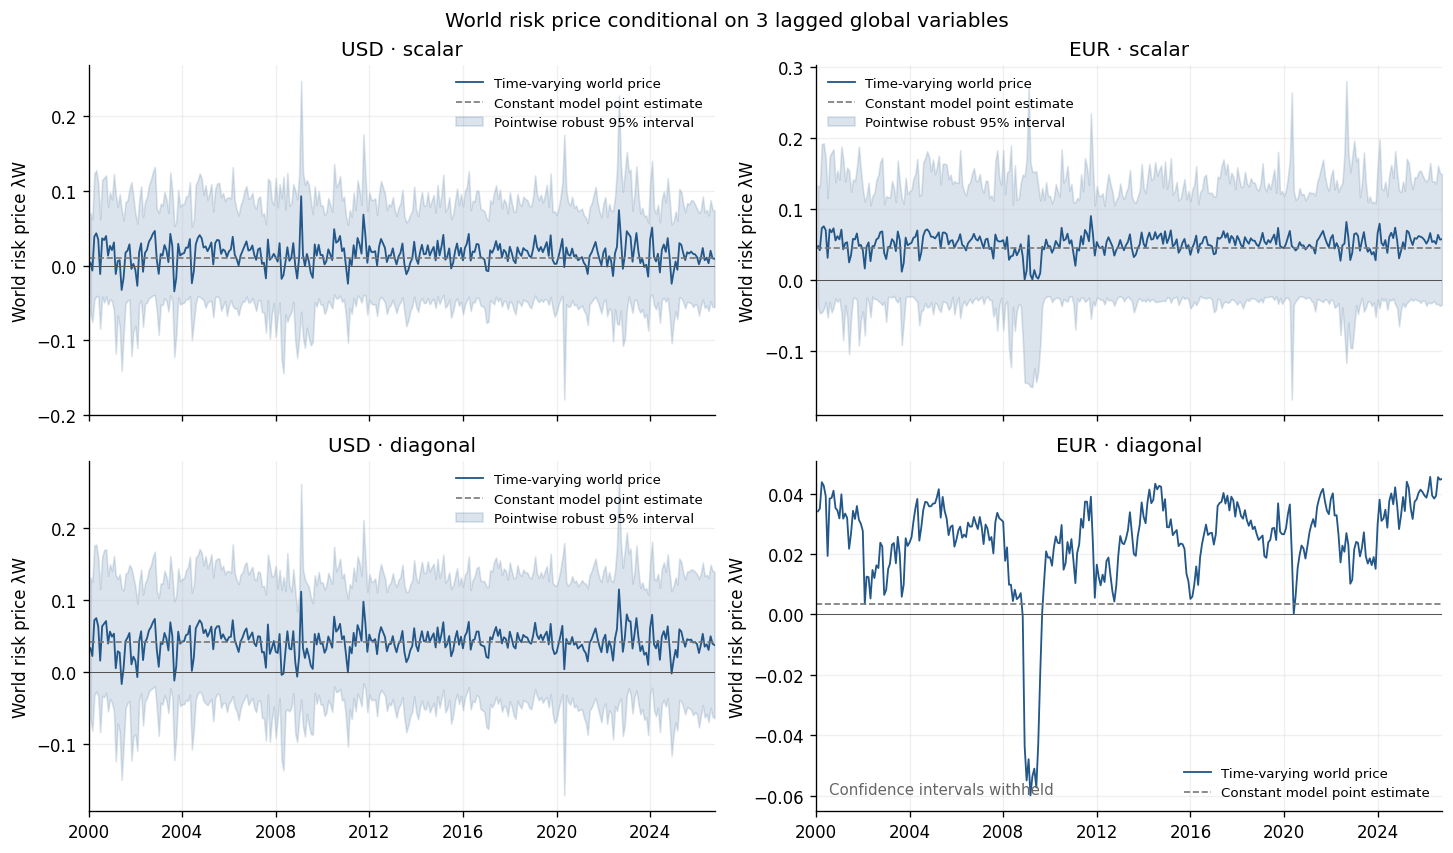

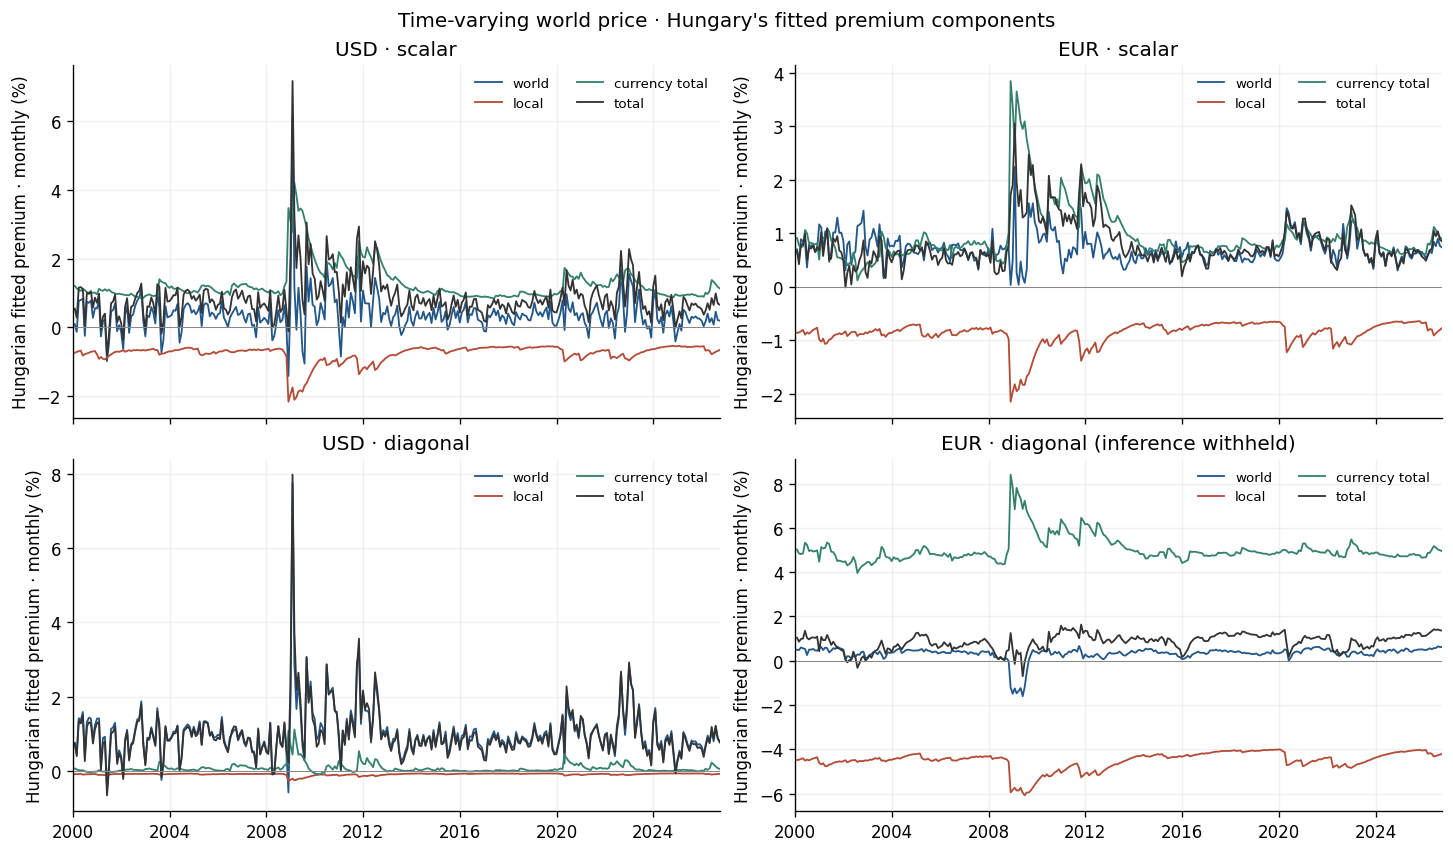

In [10]:
dates=data.index.to_timestamp("M")
fig,axes=plt.subplots(len(COVARIANCE_MODELS),2,figsize=(12,3.5*len(COVARIANCE_MODELS)),squeeze=False,sharex=True,layout="constrained")
for row,covariance_model in enumerate(COVARIANCE_MODELS):
    for col,currency in enumerate(["USD","EUR"]):
        fit=fits[f"{currency}_{covariance_model}_time_varying"]
        values=fit["filter"]["world_prices"]
        ax=axes[row,col]
        ax.plot(dates,values,color="#235789",lw=1.1,label="Time-varying world price")
        ax.axhline(fits[f"{currency}_{covariance_model}_constant"]["filter"]["prices"][0],color="#777777",ls="--",lw=1,label="Constant model point estimate")
        if fit["inference_ready"]:
            ax.fill_between(dates,values-1.96*fit["world_price_se"],values+1.96*fit["world_price_se"],color="#235789",alpha=.16,label="Pointwise robust 95% interval")
        else: ax.text(.02,.05,"Confidence intervals withheld",transform=ax.transAxes,color="#666666",fontsize=9)
        ax.axhline(0,color="#555555",lw=.6)
        ax.set(title=f"{currency} · {covariance_model}",ylabel="World risk price λW",xlim=(data.index[0].start_time,data.index[-1].end_time))
        ax.legend(frameon=False,fontsize=8)
fig.suptitle(f"World risk price conditional on {len(WORLD_INSTRUMENTS)} lagged global variables")
plt.savefig(OUT/"02_world_risk_prices.png",dpi=160,bbox_inches="tight")
plt.show();plt.close()

components={}
fig,axes=plt.subplots(len(COVARIANCE_MODELS),2,figsize=(12,3.5*len(COVARIANCE_MODELS)),squeeze=False,sharex=True,layout="constrained")
for row,covariance_model in enumerate(COVARIANCE_MODELS):
    for col,currency in enumerate(["USD","EUR"]):
        for model in ["constant","time_varying"]:
            fit=fits[f"{currency}_{covariance_model}_{model}"];f=fit["filter"];H,p=f["H"],f["prices"]
            frame=pd.DataFrame({"world":f["world_prices"]*H[:,2,0],"local":p[2]*H[:,2,2],
                                "HUF_FX":p[3]*H[:,2,3],"other_FX":p[4]*H[:,2,4]},index=data.index)
            frame["currency_total"]=frame["HUF_FX"]+frame["other_FX"]
            frame["total"]=frame["world"]+frame["local"]+frame["currency_total"]
            np.testing.assert_allclose(frame["total"],f["mu"][:,2],atol=1e-10,rtol=0)
            components[f"{currency}_{covariance_model}_{model}"]=frame
            if model=="time_varying":
                ax=axes[row,col]
                for name,color in [("world","#235789"),("local","#b34c36"),("currency_total","#34816d"),("total","#333333")]:
                    ax.plot(dates,frame[name],label=name.replace("_"," "),color=color,lw=1.1)
                ax.axhline(0,color="#888888",lw=.6)
                ax.set(title=f"{currency} · {covariance_model}"+(" (inference withheld)" if not fit["inference_ready"] else ""),
                       ylabel="Hungarian fitted premium · monthly (%)",xlim=(data.index[0].start_time,data.index[-1].end_time))
                ax.legend(frameon=False,ncol=2,fontsize=8)
fig.suptitle("Time-varying world price · Hungary's fitted premium components")
plt.savefig(OUT/"03_hungary_premium_components.png",dpi=160,bbox_inches="tight")
plt.show();plt.close()

## 9. Final comparison and reproducibility record

Read the joint constancy test alongside confidence intervals, information criteria and residual flags.
Negative changes in AIC/BIC favour the time-varying world specification. Counts of nominal 5%
diagnostic flags locate further work; they do not define an automatic model-selection rule.
Currency and local prices remain time-constant in every model here.

In [11]:
summary_rows=[]
for currency in ["USD","EUR"]:
    for covariance_model in COVARIANCE_MODELS:
        no,yes=(fit_table.loc[(currency,covariance_model,m)] for m in ["constant","time_varying"])
        fit=fits[f"{currency}_{covariance_model}_time_varying"];values=fit["filter"]["world_prices"]
        marginal=residual_table.loc[(currency,covariance_model,"time_varying")]
        cross=cross_table.loc[(currency,covariance_model,"time_varying")]
        summary_rows.append({"perspective":currency,"covariance_model":covariance_model,
            "world_constancy_p":wald_table.loc[(currency,covariance_model,"time_varying","World price constant"),"robust_p_value"],
            "world_zero_p":wald_table.loc[(currency,covariance_model,"time_varying","World price zero"),"robust_p_value"],
            "delta_AIC":yes["AIC"]-no["AIC"],"delta_BIC":yes["BIC"]-no["BIC"],
            "world_price_mean":values.mean(),"world_price_min":values.min(),"world_price_max":values.max(),
            "world_price_negative_pct":100*(values<0).mean(),
            "mean_flags":int(marginal["LB_z_p"].lt(.05).sum()),
            "variance_flags":int((marginal["LB_z_squared_p"].lt(.05)|marginal["ARCH_LM_p"].lt(.05)).sum()),
            "cross_flags":int(cross["LB_product_p"].lt(.05).sum()),"inference_ready":bool(yes["numerical_inference_ready"])})
summary=pd.DataFrame(summary_rows).set_index(["perspective","covariance_model"]).sort_index()
tables={"instrument_audit.csv":audit,"instrument_correlations.csv":instruments.corr(),
        "instrument_transform.csv":transform_table,"conditioning_design.csv":conditioning,
        "fit_summary.csv":fit_table,"price_coefficients.csv":coefficient_table,"restriction_tests.csv":wald_table,
        "starting_points.csv":starts_table,"world_price_paths.csv":world_paths,
        "residual_diagnostics.csv":residual_table,"cross_covariance_diagnostics.csv":cross_table,"summary.csv":summary}
for name,table in tables.items():table.to_csv(OUT/name,float_format="%.17g",lineterminator="\n")
for key,fit in fits.items():
    np.savez(OUT/f"parameters_{key}.npz",theta=fit["theta"],robust_covariance=fit["covariance"],
             H=fit["filter"]["H"],mu=fit["filter"]["mu"],residuals=fit["filter"]["errors"])
for key,frame in components.items():frame.to_csv(OUT/f"hungary_premium_{key.lower()}.csv",float_format="%.17g",lineterminator="\n")
record={"model_version":MODEL_VERSION,"model_code_sha256":model_code_sha256,"source_snapshot":SNAPSHOT,
    "source_dataset_sha256":manifest["exports"]["dataset.csv"],"raw_ecb_sha256":fx_source_sha256,"raw_fred_sha256":fred_sha256,
    "baseline_file_sha256":baseline_hashes,"first":str(data.index[0]),"last":str(data.index[-1]),"observations":len(data),
    "world_price":"linear in demeaned/standardized lagged global instruments; unrestricted sign",
    "world_instruments":WORLD_INSTRUMENTS,"conditioning_rank":int(np.linalg.matrix_rank(Z)),"conditioning_number":float(np.linalg.cond(Z)),
    "local_and_FX_prices":"constant and jointly re-estimated","FX_VAR_lags":FX_VAR_LAGS,
    "FX_means":"separate unrestricted jointly estimated VAR, as in notebook 05",
    "covariance_models":COVARIANCE_MODELS,"SE_step_tolerance":SE_STEP_TOL,"return_unit":"monthly log percentage points",
    "test_lags":TEST_LAGS,"packages":versions,"python":platform.python_version()}
(OUT/"estimation_manifest.json").write_text(json.dumps(record,indent=2,sort_keys=True)+"\n")
for name,expected in [("dataset.csv",manifest["exports"]["dataset.csv"]),("raw/ecb_fx.csv",fx_source_sha256),("raw/fred.csv",fred_sha256)]:
    if hashlib.sha256((source/name).read_bytes()).hexdigest()!=expected:raise ValueError("Frozen input changed.")
display(Markdown(f"**Final summary — {len(data)} matched months, {len(WORLD_INSTRUMENTS)} audited global predictors**"))
display(summary.round(4))
for (currency,covariance_model),row in summary.iterrows():
    p=row["world_constancy_p"]
    text=f"{p:.3f}" if np.isfinite(p) else "withheld (bound/curvature/SE stability gate)"
    display(Markdown(f"**{currency} · {covariance_model}:** constant-world-price Wald p = **{text}**; "
        f"time-varying minus constant AIC = **{row['delta_AIC']:+.2f}**, BIC = **{row['delta_BIC']:+.2f}**. "
        f"Residual flags: {int(row['mean_flags'])} mean, {int(row['variance_flags'])} variance, {int(row['cross_flags'])} covariance."))
if "scalar" in COVARIANCE_MODELS:
    main=summary.xs("scalar",level="covariance_model")
    if main["world_constancy_p"].notna().all() and main["world_constancy_p"].gt(.05).all():
        display(Markdown("**Main scalar reading:** neither investor perspective rejects a constant world risk price "
            "with this conditioning set. The fitted paths vary by construction; that variation is not itself evidence "
            "that the additional slopes are needed. The tests leave uncertainty about economically relevant effects."))
if summary["delta_AIC"].gt(0).all() and summary["delta_BIC"].gt(0).all():
    display(Markdown("**Model comparison:** both AIC and BIC favour the constant-world-price reference "
        "in every reported comparison. Retain the conditional fits for sensitivity analysis."))
withheld=[f"{c} · {m}" for (c,m),r in summary.iterrows() if not r["inference_ready"]]
if withheld:
    display(Markdown("**Inference withheld:** "+", ".join(withheld)+
        ". Inspect the bound, curvature and standard-error stability fields in `fit_summary.csv`; "
        "the affected component paths are illustrative."))
display(Markdown("The instruments passed alignment/rank checks; credit-spread persistence and crisis extremes remain explicit "
    "sensitivity concerns. Inference is conditional on the specification and diagnostic adequacy. "
    "Time-varying FX and Hungarian local prices are subsequent research stages. "
    f"Outputs: `{OUT.relative_to(ROOT)}`. The frozen dataset is unchanged."))

**Final summary — 321 matched months, 3 audited global predictors**

world_constancy_p  world_zero_p  delta_AIC  \
perspective covariance_model                                               
EUR         diagonal                        NaN           NaN     4.2302   
            scalar                       0.8846        0.7389     4.9031   
USD         diagonal                     0.4788        0.5209     2.4138   
            scalar                       0.5645        0.7235     3.2799   

                              delta_BIC  world_price_mean  world_price_min  \
perspective covariance_model                                                 
EUR         diagonal            15.5446            0.0248          -0.0599   
            scalar              16.2174            0.0517           0.0008   
USD         diagonal            13.7281            0.0430          -0.0164   
            scalar              14.5942            0.0160          -0.0346   

                              world_price_max  world_price_negative_pct  \
perspective covariance_model                                              
EUR         diagonal                   0.0455                    3.1153   
            scalar                     0.0903                    0.0000   
USD         diagonal                   0.1150                    2.4922   
            scalar                     0.0927                   12.7726   

                              mean_flags  variance_flags  cross_flags  \
perspective covariance_model                                            
EUR         diagonal                   1               1            0   
            scalar                     0               1            1   
USD         diagonal                   0               3            1   
            scalar                     0               4            2   

                              inference_ready  
perspective covariance_model                   
EUR         diagonal                    False  
            scalar                       True  
USD         diagonal                     True  
            scalar                       True

**EUR · diagonal:** constant-world-price Wald p = **withheld (bound/curvature/SE stability gate)**; time-varying minus constant AIC = **+4.23**, BIC = **+15.54**. Residual flags: 1 mean, 1 variance, 0 covariance.

**EUR · scalar:** constant-world-price Wald p = **0.885**; time-varying minus constant AIC = **+4.90**, BIC = **+16.22**. Residual flags: 0 mean, 1 variance, 1 covariance.

**USD · diagonal:** constant-world-price Wald p = **0.479**; time-varying minus constant AIC = **+2.41**, BIC = **+13.73**. Residual flags: 0 mean, 3 variance, 1 covariance.

**USD · scalar:** constant-world-price Wald p = **0.565**; time-varying minus constant AIC = **+3.28**, BIC = **+14.59**. Residual flags: 0 mean, 4 variance, 2 covariance.

**Main scalar reading:** neither investor perspective rejects a constant world risk price with this conditioning set. The fitted paths vary by construction; that variation is not itself evidence that the additional slopes are needed. The tests leave uncertainty about economically relevant effects.

**Model comparison:** both AIC and BIC favour the constant-world-price reference in every reported comparison. Retain the conditional fits for sensitivity analysis.

**Inference withheld:** EUR · diagonal. Inspect the bound, curvature and standard-error stability fields in `fit_summary.csv`; the affected component paths are illustrative.

The instruments passed alignment/rank checks; credit-spread persistence and crisis extremes remain explicit sensitivity concerns. Inference is conditional on the specification and diagnostic adequacy. Time-varying FX and Hungarian local prices are subsequent research stages. Outputs: `output/06_time_varying_world/fixed_2026-11-13/2000-01_2026-09/var6_zc1170c40`. The frozen dataset is unchanged.